# Clasificación de tumores de mama con aprendizaje supervisado

**Autoras:** Antía Sande Fernández y Candela Espinar Paisan
**Asignatura:** Aprendizaje Automático I · Grado en Ciencia de Datos e Inteligencia Artificial (UPM) · curso 2025-26

El objetivo es predecir si un tumor de mama es **benigno (0)** o **maligno (1)** a partir de 30 características morfológicas de los núcleos celulares, medidas sobre imágenes digitales de una punción (dataset *Breast Cancer Wisconsin Diagnostic*).

Se comparan cuatro modelos supervisados:

- Regresión Logística
- Árbol de Decisión
- K-Vecinos más cercanos (K-NN)
- Máquinas de Vectores Soporte (SVM)

**Contenido del notebook**

1. Carga y limpieza de los datos
2. Análisis exploratorio (EDA)
3. Preparación: división train/test y pipelines
4. Ajuste de hiperparámetros con `GridSearchCV`
5. Evaluación en test: métricas, matrices de confusión, curvas ROC y calibración
6. Interpretación del Árbol de Decisión
7. Ampliación: ajuste del umbral de decisión para reducir falsos negativos
8. Conclusiones

> **Por qué importan tanto los falsos negativos.** En este problema los errores no cuestan lo mismo. Un **falso negativo** (decir "benigno" a un tumor maligno) puede retrasar un tratamiento, mientras que un **falso positivo** lleva a pruebas adicionales. Por eso, además de la *accuracy*, se analizan el **recall de la clase maligna** y el número de falsos negativos.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("Dark2")

RANDOM_STATE = 42                     # semilla fija para que los resultados sean reproducibles
DATA_PATH = Path("../data/Cancer_Data.csv")
FIG_DIR = Path("../docs/img")         # aquí se guardan las figuras que usa el README
FIG_DIR.mkdir(parents=True, exist_ok=True)
COLORES = {"Benigno": "#2a9d8f", "Maligno": "#e76f51"}


def guardar(nombre):
    # Guarda la figura actual en docs/img para usarla en el README.
    plt.savefig(FIG_DIR / f"{nombre}.png", dpi=130, bbox_inches="tight")

## 1. Carga y limpieza de los datos

El fichero tiene 569 tumores y 33 columnas. La limpieza consiste en:

- Eliminar `Unnamed: 32`, una columna vacía que aparece por una coma final en el CSV.
- Eliminar `id`, que solo identifica al paciente y no aporta información predictiva.
- Codificar la variable objetivo `diagnosis`: **B → 0** (benigno) y **M → 1** (maligno).
- Comprobar que no hay valores nulos ni filas duplicadas.

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Dimensiones originales:", df_raw.shape)

df = (
    df_raw
    .drop(columns=["id", "Unnamed: 32"])
    .assign(diagnosis=lambda d: d["diagnosis"].map({"B": 0, "M": 1}))
)

print("Dimensiones tras la limpieza:", df.shape)
print("Valores nulos:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
print("\nDistribución de la variable objetivo:")
print(df["diagnosis"].value_counts().rename({0: "Benigno (0)", 1: "Maligno (1)"}).to_string())

Dimensiones originales: (569, 33)
Dimensiones tras la limpieza: (569, 31)
Valores nulos: 0
Filas duplicadas: 0

Distribución de la variable objetivo:
diagnosis
Benigno (0)    357
Maligno (1)    212


Las 30 variables explicativas son **10 medidas** de los núcleos celulares (radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal), cada una resumida de tres formas:

| Sufijo | Significado |
|---|---|
| `_mean` | media de la medida en todos los núcleos de la imagen |
| `_se` | error estándar de la medida |
| `_worst` | media de los tres valores más extremos ("peor caso") |

Las clases están algo desbalanceadas (≈63 % benignos, 37 % malignos). Por eso, en la división train/test, se usa **estratificación**.

## 2. Análisis exploratorio (EDA)

### 2.1 Distribución de las variables y escalas

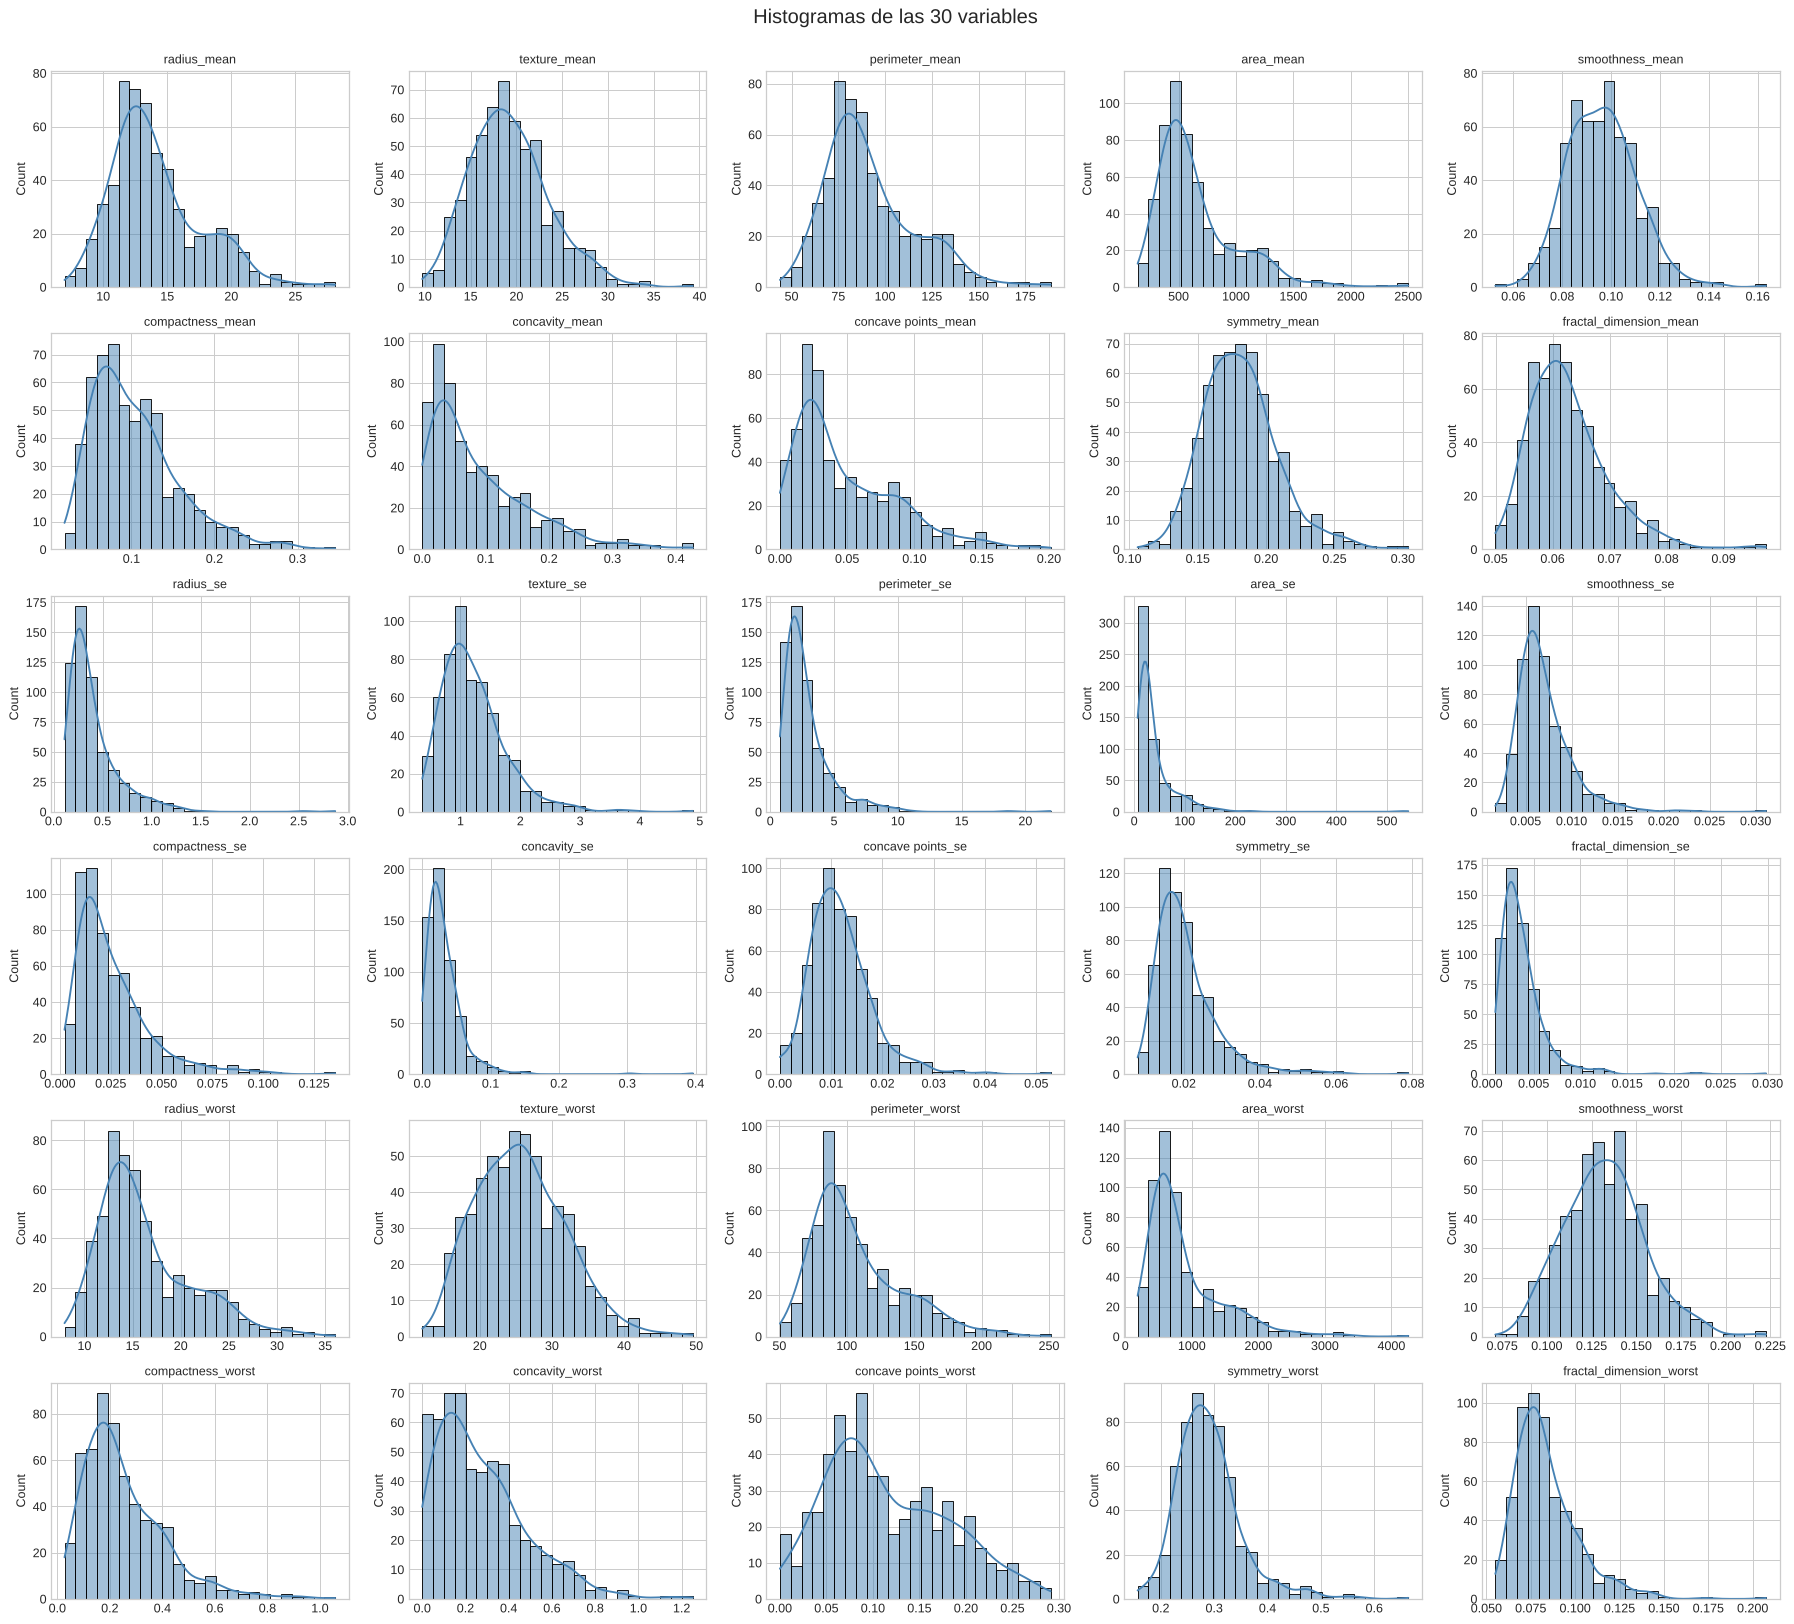

Rango de escalas (desviación típica mínima y máxima):
min      0.0026
max    569.3570


In [3]:
X_all = df.drop(columns="diagnosis")

fig, axes = plt.subplots(6, 5, figsize=(20, 18))
for ax, col in zip(axes.ravel(), X_all.columns):
    sns.histplot(X_all[col], bins=25, kde=True, ax=ax, color="steelblue")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
fig.suptitle("Histogramas de las 30 variables", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

print("Rango de escalas (desviación típica mínima y máxima):")
print(X_all.std().agg(["min", "max"]).round(4).to_string())

- Muchas variables tienen **distribuciones asimétricas a la derecha** (colas largas), algo habitual en medidas de tamaño.
- Las **escalas son muy distintas**: `area_worst` llega a miles, mientras que `fractal_dimension_se` está en milésimas. Los modelos basados en distancias (K-NN, SVM) y la Regresión Logística regularizada necesitan **estandarizar** las variables. El escalado se hace dentro de un `Pipeline` para evitar *data leakage*.

### 2.2 Correlación entre variables

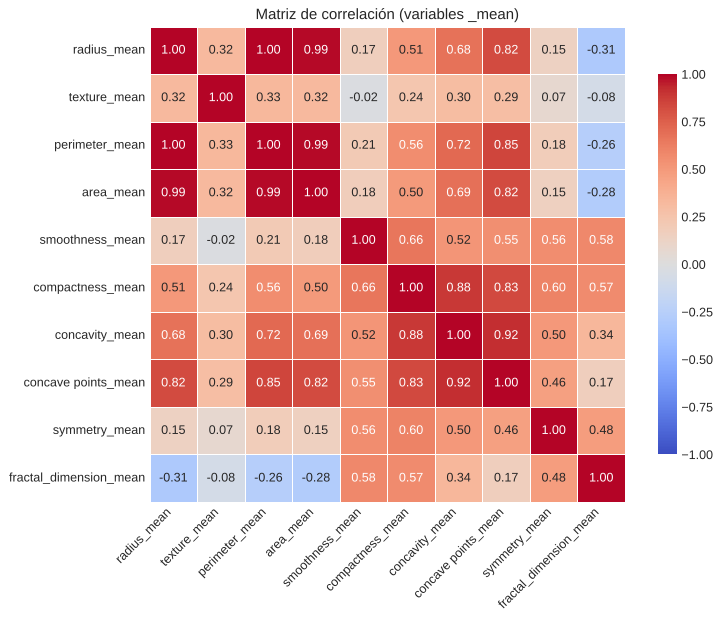

In [4]:
mean_cols = [c for c in X_all.columns if c.endswith("_mean")]

plt.figure(figsize=(9, 7))
sns.heatmap(df[mean_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Matriz de correlación (variables _mean)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
guardar("correlacion")
plt.show()

Hay una **fuerte multicolinealidad**: `radius_mean`, `perimeter_mean` y `area_mean` tienen correlaciones superiores a 0,99, lo cual tiene sentido geométrico porque las tres miden el tamaño del núcleo. Lo mismo ocurre entre `concavity`, `concave points` y `compactness`.

Esto no afecta a la capacidad predictiva, pero hace que los coeficientes de la Regresión Logística sean menos interpretables de forma individual. La regularización (parámetro `C`) ayuda a controlarlo.

### 2.3 Separación entre clases

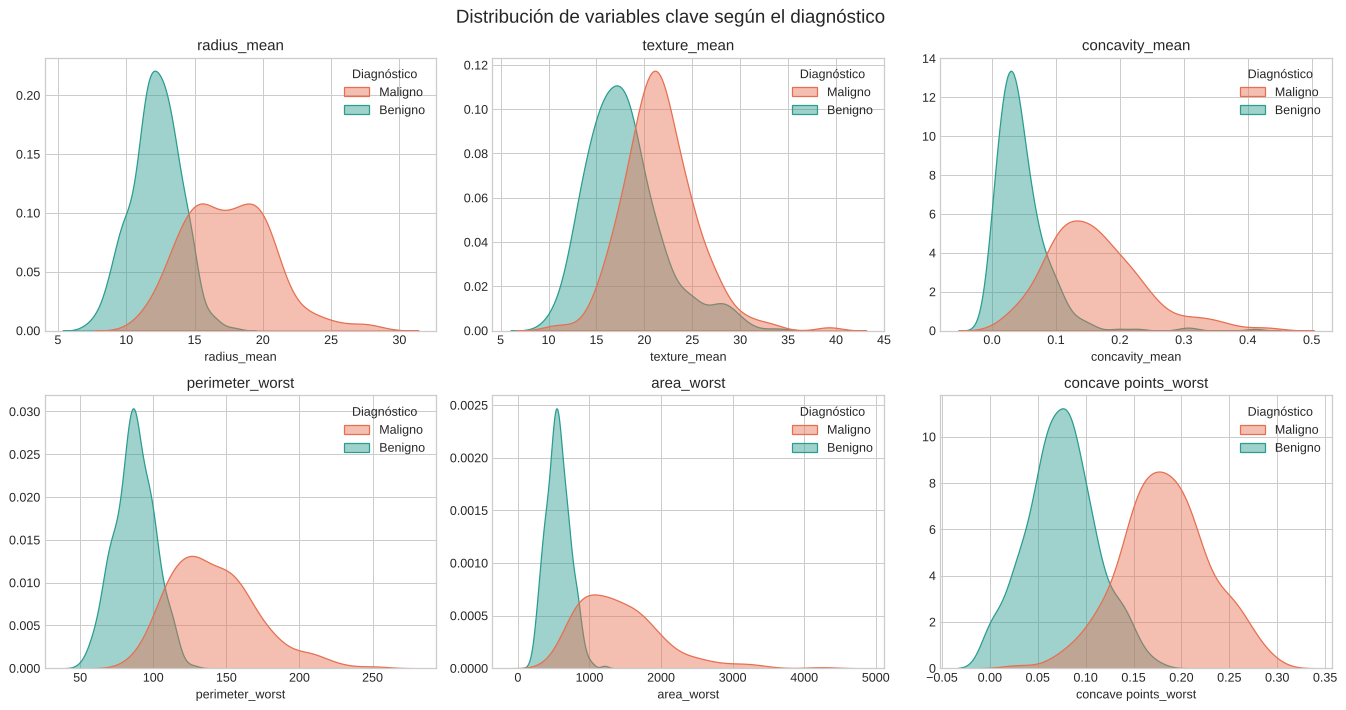

In [5]:
vars_clave = ["radius_mean", "texture_mean", "concavity_mean",
              "perimeter_worst", "area_worst", "concave points_worst"]

df_plot = df.assign(Diagnóstico=df["diagnosis"].map({0: "Benigno", 1: "Maligno"}))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), vars_clave):
    sns.kdeplot(data=df_plot, x=col, hue="Diagnóstico", fill=True, alpha=0.45,
                common_norm=False, palette=COLORES, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
fig.suptitle("Distribución de variables clave según el diagnóstico", fontsize=15)
plt.tight_layout()
guardar("distribucion_por_clase")
plt.show()

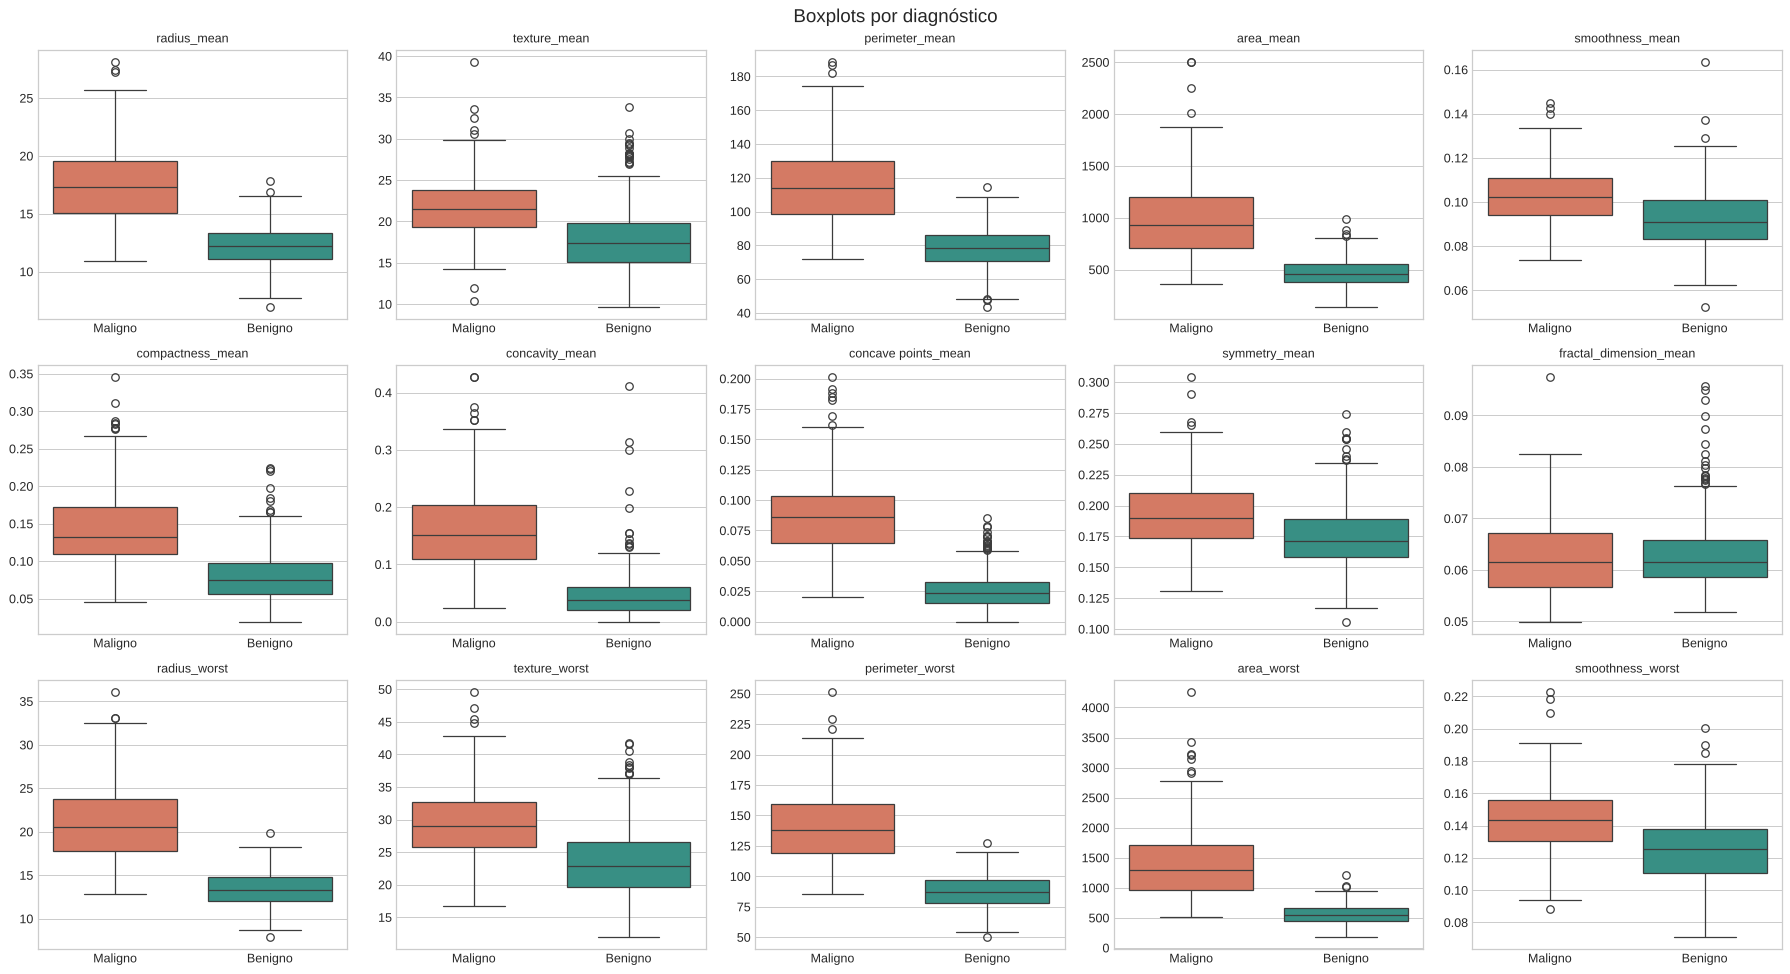

In [6]:
fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for ax, col in zip(axes.ravel(), mean_cols + [c for c in X_all.columns if c.endswith("_worst")][:5]):
    sns.boxplot(data=df_plot, x="Diagnóstico", y=col, hue="Diagnóstico", palette=COLORES,
                legend=False, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Boxplots por diagnóstico", fontsize=15)
plt.tight_layout()
plt.show()

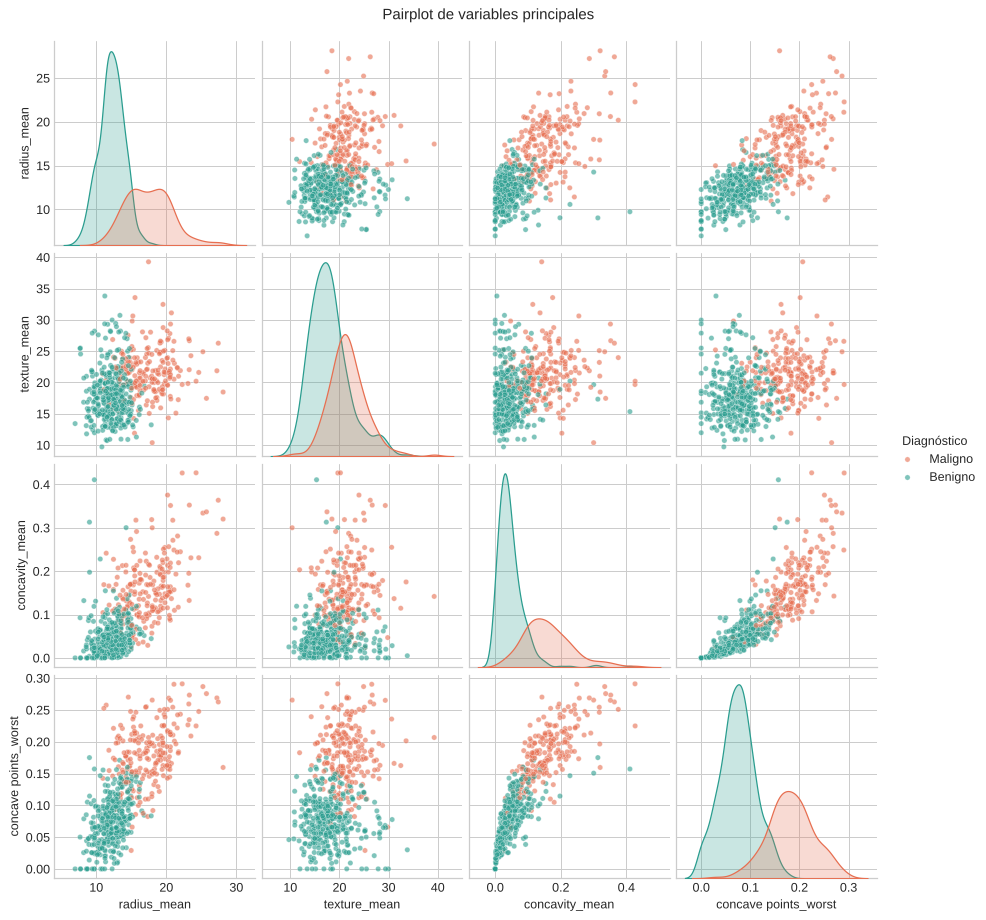

In [7]:
sns.pairplot(df_plot[["radius_mean", "texture_mean", "concavity_mean", "concave points_worst", "Diagnóstico"]],
             hue="Diagnóstico", palette=COLORES, diag_kind="kde", plot_kws={"alpha": 0.6, "s": 18})
plt.suptitle("Pairplot de variables principales", y=1.02)
plt.show()

**Conclusiones del EDA**

- Las variables de **tamaño** (`radius`, `perimeter`, `area`) y de **forma irregular** (`concavity`, `concave points`) toman valores claramente mayores en los tumores malignos. `perimeter_worst`, `area_worst` y `concave points_worst` son las que mejor separan las dos clases, con poco solapamiento entre ellas.
- `texture`, `symmetry` y `fractal_dimension` presentan bastante más solapamiento.
- En el pairplot, las clases forman nubes bien diferenciadas con una frontera **casi lineal**. Esto anticipa que modelos sencillos como la Regresión Logística pueden funcionar muy bien.

## 3. Preparación: división train/test y pipelines

- **70 % entrenamiento / 30 % test**, estratificado para mantener la proporción de clases. El conjunto de test **no se usa** hasta la evaluación final.
- Cada modelo es un `Pipeline` con `StandardScaler` + clasificador. Así, en cada fold de la validación cruzada el escalado se ajusta solo con los datos de entrenamiento de ese fold.

In [8]:
X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]} muestras ({y_train.mean():.1%} malignos)")
print(f"Test:  {X_test.shape[0]} muestras ({y_test.mean():.1%} malignos)")

Train: 398 muestras (37.2% malignos)
Test:  171 muestras (37.4% malignos)


## 4. Ajuste de hiperparámetros con `GridSearchCV`

Para cada modelo se define una rejilla de hiperparámetros y se busca la mejor combinación con **validación cruzada de 5 folds** sobre el conjunto de entrenamiento, usando la *accuracy* como métrica de selección.

| Modelo | Hiperparámetros explorados | Qué controlan |
|---|---|---|
| Regresión Logística | `C`, `solver` | Fuerza de la regularización |
| Árbol de Decisión | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` | Complejidad del árbol (sobreajuste) |
| K-NN | `n_neighbors`, `weights`, `p` | Tamaño del vecindario y tipo de distancia (Manhattan / euclídea) |
| SVM | `kernel`, `C`, `gamma` | Forma de la frontera y anchura del margen |

In [9]:
def crear_pipeline(modelo):
    return Pipeline([("scaler", StandardScaler()), ("model", modelo)])


modelos = {
    "Regresión Logística": (
        LogisticRegression(max_iter=5000),
        {"model__C": [0.01, 0.1, 1, 10], "model__solver": ["lbfgs", "liblinear"]},
    ),
    "Árbol de Decisión": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"model__max_depth": [None, 3, 5, 8, 10],
         "model__min_samples_split": [2, 5, 10],
         "model__min_samples_leaf": [1, 2, 4],
         "model__criterion": ["gini", "entropy"]},
    ),
    "K-NN": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [3, 5, 7, 9, 11],
         "model__weights": ["uniform", "distance"],
         "model__p": [1, 2]},
    ),
    "SVM": (
        SVC(random_state=RANDOM_STATE),
        {"model__kernel": ["linear", "rbf"],
         "model__C": [0.1, 1, 10, 100],
         "model__gamma": ["scale", 0.01, 0.001]},
    ),
}

mejores = {}
filas_cv = []
for nombre, (modelo, rejilla) in modelos.items():
    grid = GridSearchCV(crear_pipeline(modelo), rejilla, cv=5, scoring="accuracy", n_jobs=-1)
    grid.fit(X_train, y_train)
    mejores[nombre] = grid.best_estimator_
    params = {k.replace("model__", ""): v for k, v in grid.best_params_.items()}
    filas_cv.append({"Modelo": nombre, "Accuracy CV": grid.best_score_, "Mejores hiperparámetros": params})

tabla_cv = pd.DataFrame(filas_cv).sort_values("Accuracy CV", ascending=False).reset_index(drop=True)
display(tabla_cv.style.format({"Accuracy CV": "{:.4f}"}).hide(axis="index"))

Modelo,Accuracy CV,Mejores hiperparámetros
Regresión Logística,0.9748,"{'C': 1, 'solver': 'liblinear'}"
SVM,0.9747,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}"
K-NN,0.9698,"{'n_neighbors': 11, 'p': 1, 'weights': 'distance'}"
Árbol de Decisión,0.9396,"{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 10}"


**Interpretación de los hiperparámetros elegidos**

- **Regresión Logística (`C = 1`):** una regularización moderada es suficiente; la frontera lineal ya separa muy bien las clases.
- **SVM (kernel RBF, `C = 10`, `gamma = "scale"`):** obtiene prácticamente la misma *accuracy* que la Regresión Logística. El kernel RBF permite curvar un poco la frontera en las zonas de solapamiento.
- **K-NN (`k = 11`, distancia Manhattan, ponderación por distancia):** un vecindario grande estabiliza la predicción, y ponderar por distancia da más peso a los vecinos más cercanos.
- **Árbol de Decisión:** es el que peor rinde en validación cruzada. Además, es **inestable**: pequeñas variaciones de los datos o de la semilla cambian la estructura del árbol elegido (en la entrega original salió un árbol sin límite de profundidad; con la semilla fija de este notebook, uno de profundidad 3).

## 5. Evaluación en el conjunto de test

### 5.1 Métricas

In [10]:
def puntuaciones(modelo, X_):
    # Probabilidad de 'maligno' si el modelo la ofrece; si no (SVM), distancia a la frontera.
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X_)[:, 1]
    return modelo.decision_function(X_)


filas = []
for nombre, modelo in mejores.items():
    y_pred = modelo.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    filas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Recall (maligno)": recall_score(y_test, y_pred),
        "Precisión (maligno)": precision_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, puntuaciones(modelo, X_test)),
        "Falsos negativos": fn,
        "Falsos positivos": fp,
    })

resultados = pd.DataFrame(filas).sort_values(["Accuracy", "Recall (maligno)"], ascending=False).reset_index(drop=True)
display(resultados.style.format({c: "{:.3f}" for c in ["Accuracy", "Recall (maligno)", "Precisión (maligno)", "F1", "AUC"]})
        .highlight_max(subset=["Accuracy", "Recall (maligno)", "AUC"], color="#d8f3dc")
        .highlight_min(subset=["Falsos negativos"], color="#d8f3dc")
        .hide(axis="index"))

Modelo,Accuracy,Recall (maligno),Precisión (maligno),F1,AUC,Falsos negativos,Falsos positivos
Regresión Logística,0.971,0.938,0.984,0.960,0.998,4,1
SVM,0.971,0.938,0.984,0.960,0.995,4,1
K-NN,0.965,0.906,1.000,0.951,0.999,6,0
Árbol de Decisión,0.918,0.781,1.000,0.877,0.919,14,0


In [11]:
for nombre, modelo in mejores.items():
    print(f"=== {nombre} ===")
    print(classification_report(y_test, modelo.predict(X_test), target_names=["Benigno", "Maligno"], digits=3))

=== Regresión Logística ===
              precision    recall  f1-score   support

     Benigno      0.964     0.991     0.977       107
     Maligno      0.984     0.938     0.960        64

    accuracy                          0.971       171
   macro avg      0.974     0.964     0.968       171
weighted avg      0.971     0.971     0.971       171

=== Árbol de Decisión ===
              precision    recall  f1-score   support

     Benigno      0.884     1.000     0.939       107
     Maligno      1.000     0.781     0.877        64

    accuracy                          0.918       171
   macro avg      0.942     0.891     0.908       171
weighted avg      0.928     0.918     0.916       171

=== K-NN ===
              precision    recall  f1-score   support

     Benigno      0.947     1.000     0.973       107
     Maligno      1.000     0.906     0.951        64

    accuracy                          0.965       171
   macro avg      0.973     0.953     0.962       171
weighte

- **Regresión Logística y SVM empatan** como mejores modelos: 97,1 % de *accuracy*, con solo **4 falsos negativos** y 1 falso positivo sobre 171 casos de test.
- **K-NN** tiene la AUC más alta (0,999) y ningún falso positivo, pero confunde 6 tumores malignos con benignos.
- El **Árbol de Decisión** queda claramente por detrás: es el que más falsos negativos comete.
- La *accuracy* en test es muy parecida a la de validación cruzada en los tres mejores modelos, así que **no hay indicios de sobreajuste**.

### 5.2 Matrices de confusión

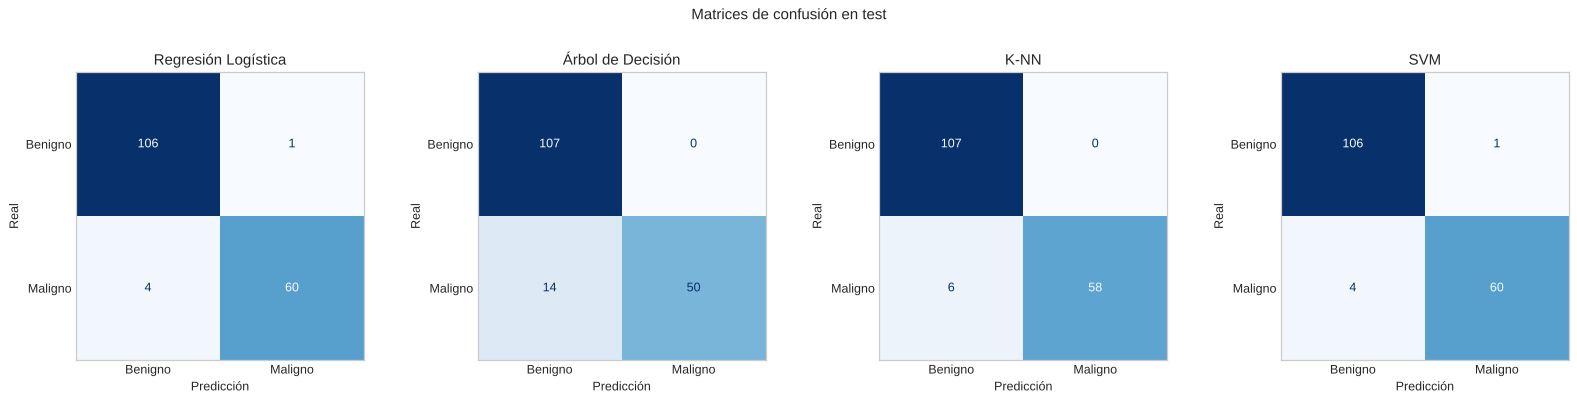

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (nombre, modelo) in zip(axes, mejores.items()):
    ConfusionMatrixDisplay.from_estimator(
        modelo, X_test, y_test, display_labels=["Benigno", "Maligno"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
    ax.grid(False)
fig.suptitle("Matrices de confusión en test", y=1.03)
plt.tight_layout()
guardar("matrices_confusion")
plt.show()

### 5.3 Curvas ROC

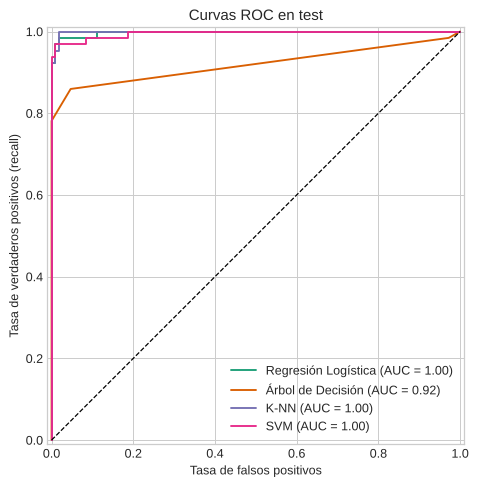

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nombre, modelo in mejores.items():
    RocCurveDisplay.from_predictions(y_test, puntuaciones(modelo, X_test), name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.set_title("Curvas ROC en test")
plt.tight_layout()
guardar("curvas_roc")
plt.show()

Las curvas ROC de Regresión Logística, SVM y K-NN están casi pegadas a la esquina superior izquierda (AUC ≥ 0,995): los tres **ordenan** muy bien los tumores según su riesgo. La diferencia entre ellos está en cómo de bien se sitúa el umbral de decisión, que es lo que se aborda en la sección 7.

### 5.4 Calibración de las probabilidades

En un contexto clínico no basta con clasificar: interesa que una probabilidad del 80 % signifique realmente un 80 % de riesgo. La **curva de calibración** compara la probabilidad predicha con la frecuencia real de malignos, y el **Brier score** mide el error cuadrático de esas probabilidades (cuanto menor, mejor).

La SVM no está incluida, porque `SVC` no produce probabilidades sino distancias al hiperplano, que no son directamente interpretables como riesgo.

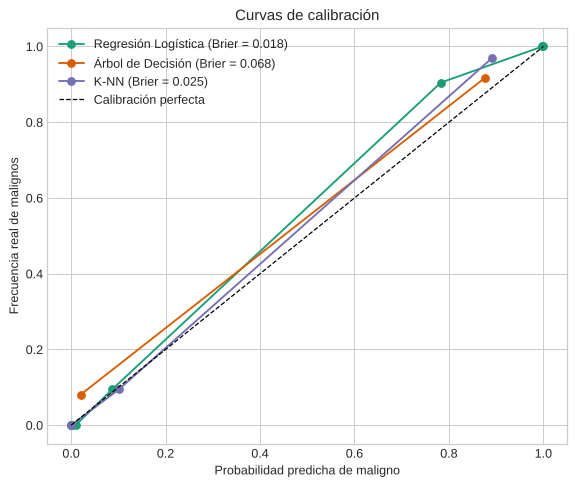

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nombre, modelo in mejores.items():
    if not hasattr(modelo, "predict_proba"):
        continue
    prob = modelo.predict_proba(X_test)[:, 1]
    frac_real, prob_media = calibration_curve(y_test, prob, n_bins=8, strategy="quantile")
    ax.plot(prob_media, frac_real, marker="o",
            label=f"{nombre} (Brier = {brier_score_loss(y_test, prob):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Calibración perfecta")
ax.set_xlabel("Probabilidad predicha de maligno")
ax.set_ylabel("Frecuencia real de malignos")
ax.set_title("Curvas de calibración")
ax.legend()
plt.tight_layout()
plt.show()

La **Regresión Logística** es el modelo mejor calibrado (menor Brier score): sus probabilidades se pueden interpretar como un riesgo estimado. Esto, junto con su sencillez e interpretabilidad, la convierte en la opción más recomendable para este problema.

## 6. Interpretación del Árbol de Decisión

Aunque es el modelo con peor rendimiento, el árbol tiene una ventaja: sus reglas se pueden leer directamente. Como el árbol se entrena sobre datos estandarizados, los umbrales están en **unidades de desviación típica**. Para que las reglas sean legibles, se convierten de vuelta a las **unidades originales** de cada variable.

Profundidad del árbol: 3 | Hojas: 6


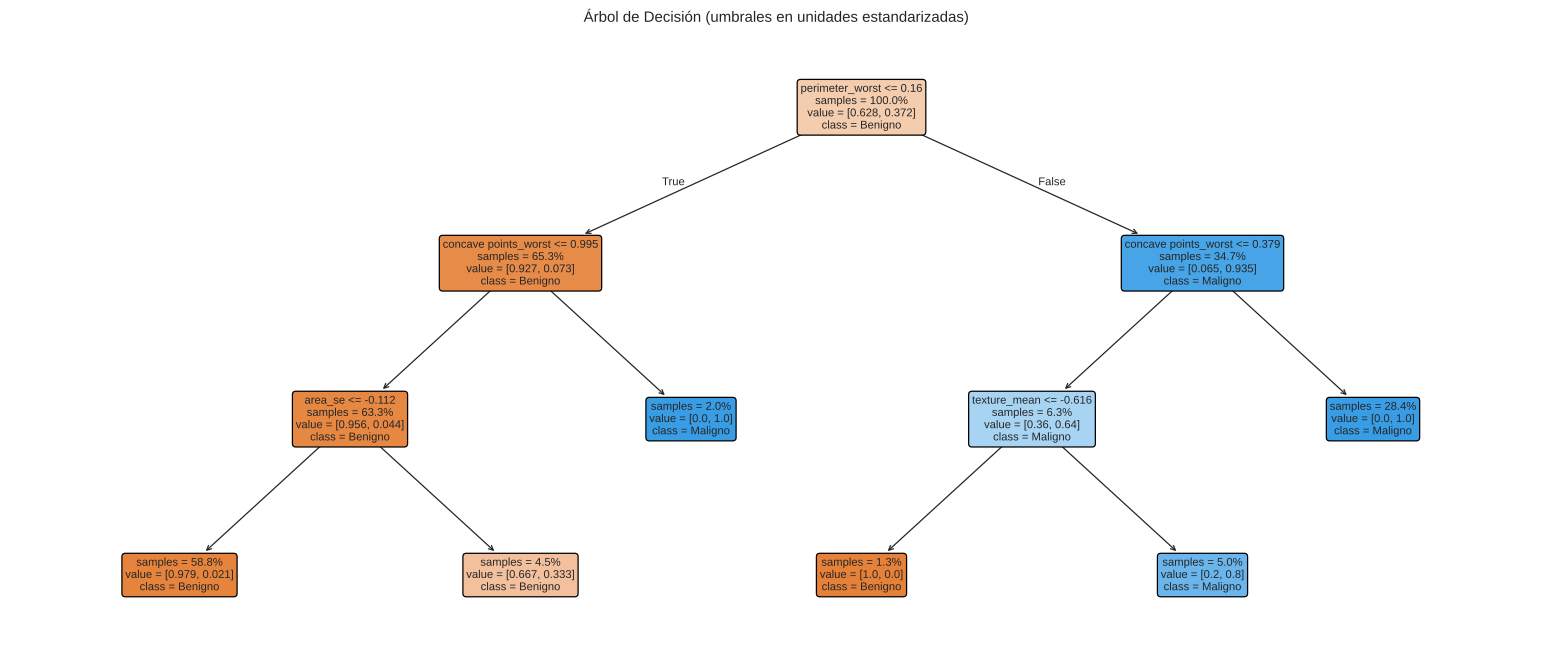

In [15]:
arbol_pipe = mejores["Árbol de Decisión"]
arbol = arbol_pipe.named_steps["model"]
scaler = arbol_pipe.named_steps["scaler"]

print("Profundidad del árbol:", arbol.get_depth(), "| Hojas:", arbol.get_n_leaves())

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(arbol, feature_names=X.columns, class_names=["Benigno", "Maligno"],
          filled=True, rounded=True, fontsize=9, max_depth=3, impurity=False, proportion=True, ax=ax)
ax.set_title("Árbol de Decisión (umbrales en unidades estandarizadas)")
plt.show()

In [16]:
# Reglas del árbol con los umbrales en las unidades originales de cada variable
t = arbol.tree_
umbral_original = t.threshold.copy()
internos = t.feature >= 0
umbral_original[internos] = (scaler.mean_[t.feature[internos]]
                             + t.threshold[internos] * scaler.scale_[t.feature[internos]])


def imprimir_reglas(nodo=0, sangria=""):
    if t.feature[nodo] < 0:  # hoja
        valores = t.value[nodo][0]
        clase = ["Benigno", "Maligno"][int(np.argmax(valores))]
        print(f"{sangria}→ {clase}  ({int(t.n_node_samples[nodo])} muestras de train)")
        return
    var = X.columns[t.feature[nodo]]
    u = umbral_original[nodo]
    print(f"{sangria}si {var} <= {u:.4g}:")
    imprimir_reglas(t.children_left[nodo], sangria + "    ")
    print(f"{sangria}si {var} > {u:.4g}:")
    imprimir_reglas(t.children_right[nodo], sangria + "    ")


imprimir_reglas()

si perimeter_worst <= 112.8:
    si concave points_worst <= 0.1807:
        si area_se <= 35.43:
            → Benigno  (234 muestras de train)
        si area_se > 35.43:
            → Benigno  (18 muestras de train)
    si concave points_worst > 0.1807:
        → Maligno  (8 muestras de train)
si perimeter_worst > 112.8:
    si concave points_worst <= 0.1399:
        si texture_mean <= 16.78:
            → Benigno  (5 muestras de train)
        si texture_mean > 16.78:
            → Maligno  (20 muestras de train)
    si concave points_worst > 0.1399:
        → Maligno  (113 muestras de train)


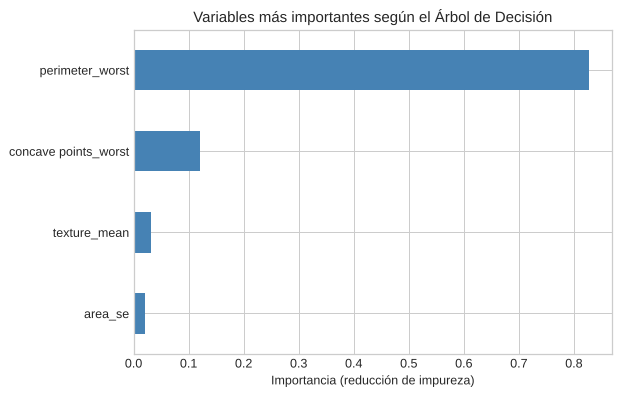

,Importancia
perimeter_worst,0.828
concave points_worst,0.120
texture_mean,0.032
area_se,0.020


In [17]:
importancias = pd.Series(arbol.feature_importances_, index=X.columns).sort_values(ascending=False)
importancias = importancias[importancias > 0]   # el árbol solo usa unas pocas variables

fig, ax = plt.subplots(figsize=(7, 4.5))
importancias.sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_title("Variables más importantes según el Árbol de Decisión")
ax.set_xlabel("Importancia (reducción de impureza)")
plt.tight_layout()
plt.show()
display(importancias.round(3).to_frame("Importancia"))

Las reglas confirman lo visto en el EDA. El árbol decide casi solo con dos variables: el **tamaño en el peor caso** (`perimeter_worst`, más del 80 % de la importancia) y la **irregularidad del contorno** (`concave points_worst`). `texture_mean` y `area_se` solo intervienen en casos dudosos. Un tumor grande y con muchos puntos cóncavos se clasifica como maligno. Estas variables coinciden con los criterios morfológicos que se usan en citología.

## 7. Ampliación: ajuste del umbral para reducir los falsos negativos

*Esta sección se añadió después de la entrega, como desarrollo de una de las mejoras propuestas.*

Por defecto, un clasificador predice "maligno" si la probabilidad es ≥ 0,5. Pero si un falso negativo es mucho más grave que un falso positivo, conviene **bajar el umbral**: así se marcan como sospechosos más casos dudosos, a cambio de algunas pruebas extra.

Para no "hacer trampa" con el conjunto de test, el umbral se elige **solo con datos de entrenamiento**, usando predicciones de validación cruzada (`cross_val_predict`). El criterio es elegir el umbral que **maximiza el recall** manteniendo una **precisión ≥ 0,93**. Después se aplica una única vez al test.

Umbral elegido con validación cruzada: 0.30


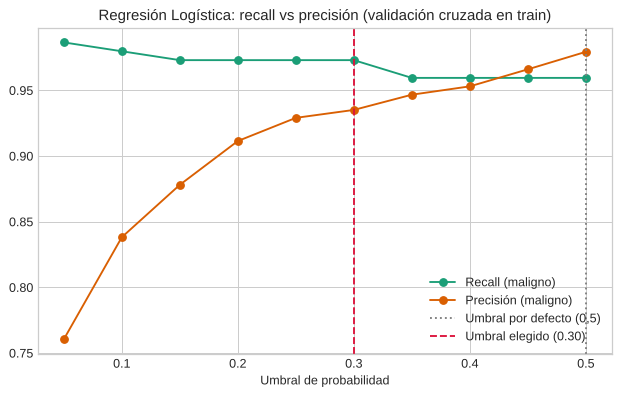

In [18]:
lr = mejores["Regresión Logística"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
prob_cv = cross_val_predict(lr, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

umbrales = np.round(np.arange(0.05, 0.55, 0.05), 2)
curva = pd.DataFrame({
    "Umbral": umbrales,
    "Recall CV": [recall_score(y_train, prob_cv >= u) for u in umbrales],
    "Precisión CV": [precision_score(y_train, prob_cv >= u) for u in umbrales],
})

candidatos = curva[curva["Precisión CV"] >= 0.93]
umbral = candidatos.sort_values(["Recall CV", "Precisión CV"], ascending=False).iloc[0]["Umbral"]
print(f"Umbral elegido con validación cruzada: {umbral:.2f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(curva["Umbral"], curva["Recall CV"], marker="o", label="Recall (maligno)")
ax.plot(curva["Umbral"], curva["Precisión CV"], marker="o", label="Precisión (maligno)")
ax.axvline(0.5, color="gray", ls=":", label="Umbral por defecto (0,5)")
ax.axvline(umbral, color="crimson", ls="--", label=f"Umbral elegido ({umbral:.2f})")
ax.set_xlabel("Umbral de probabilidad")
ax.set_title("Regresión Logística: recall vs precisión (validación cruzada en train)")
ax.legend()
plt.tight_layout()
guardar("ajuste_umbral")
plt.show()

In [19]:
prob_test = lr.predict_proba(X_test)[:, 1]
comparacion = []
for etiqueta, u in [("Umbral 0,50 (por defecto)", 0.5), (f"Umbral {umbral:.2f} (ajustado)".replace(".", ","), umbral)]:
    pred = (prob_test >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    comparacion.append({"": etiqueta, "Accuracy": accuracy_score(y_test, pred),
                        "Recall (maligno)": recall_score(y_test, pred),
                        "Precisión (maligno)": precision_score(y_test, pred),
                        "Falsos negativos": fn, "Falsos positivos": fp})

display(pd.DataFrame(comparacion).style.format({"Accuracy": "{:.3f}", "Recall (maligno)": "{:.3f}",
                                                 "Precisión (maligno)": "{:.3f}"}).hide(axis="index"))

,Accuracy,Recall (maligno),Precisión (maligno),Falsos negativos,Falsos positivos
"Umbral 0,50 (por defecto)",0.971,0.938,0.984,4,1
"Umbral 0,30 (ajustado)",0.982,0.969,0.984,2,1


Con el umbral ajustado, la Regresión Logística **reduce a la mitad los falsos negativos en test (de 4 a 2)** sin añadir ningún falso positivo. El umbral se ha elegido sin mirar el test, así que la mejora es una estimación honesta de lo que pasaría con pacientes nuevos. Eso sí, con solo 64 malignos en test, cada caso pesa mucho y la cifra exacta tiene bastante incertidumbre.

## 8. Conclusiones

- Las características morfológicas del dataset **separan muy bien** tumores benignos y malignos, con una frontera casi lineal.
- **Regresión Logística y SVM** son los mejores modelos (97,1 % de *accuracy*, AUC > 0,995, 4 falsos negativos en 171 casos). Entre los dos, la **Regresión Logística es la opción recomendada**: es más sencilla, más interpretable y está mejor calibrada, así que sus probabilidades se pueden leer como riesgo.
- **K-NN** discrimina muy bien (mayor AUC) pero comete más falsos negativos. El **Árbol de Decisión** es el peor y el más inestable, aunque resulta útil para entender qué variables importan: tamaño y concavidad en el "peor caso".
- **Ajustar el umbral** de decisión, eligiéndolo solo con datos de entrenamiento, permite reducir aún más los falsos negativos, que son el error más grave en un contexto clínico.

**Posibles líneas futuras** (fuera del alcance de la práctica, que no permitía PCA ni *ensembles*): eliminar variables redundantes o aplicar PCA para reducir la multicolinealidad, probar Random Forest o Gradient Boosting, y validar los resultados con una validación cruzada repetida para tener intervalos de confianza de las métricas.